# 10 — Geo-morphology, topography and wind features

Tests the new static geo-feature families (section 0 of the plan) added by
`scripts/build_static_features.py`: Terrain (T), Morphology (M), Roof (R),
Wind (W) and Shadow (S). Protocol mirrors notebook 06 exactly: inner LOSO
over the **27 development sensors only** — the 12-sensor lockbox stays
closed, same as every notebook before 07.

**W/S caveat:** `fai_upwind_250`, `fetch_ndvi_500`, `wind_eff`, `shaded`,
`shade_frac_3h`, `shade_hours_cum` are genuinely time-varying by design, but
`static_geo_durham.parquet` only carries their **one-week time-average**
(`*_mean` columns) — the full hourly dynamic table
(`static_geo_durham_dynamic.parquet`) covers one week only, a runtime-bounded
subsample, not the full season. So W and S enter this ablation as *static
per-sensor proxies*, not true per-hour dynamics. If either looks promising
here, wiring in the real per-hour values is the natural next step before
trusting the result.


In [1]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.outliers_influence import variance_inflation_factor

from urbansense_common import (
    load_data, sensor_level_split, split_day_night, fit_xgb, regression_metrics,
    X_NAMES_AT_DAY, X_NAMES_AT_NIGHT, XGB_PARAMS_FAST,
)
from network_features import build_network_features, haversine_matrix
from temporal_features import add_temporal_features
from spatial_cv import per_sensor_metrics, paired_wilcoxon, sensor_bootstrap_ci

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60)

data = load_data(geo=True)
train_sensor_ids, test_sensor_ids = sensor_level_split(data)
dev_ids = list(train_sensor_ids)
dev = data[data["Sensor_ID"].isin(dev_ids)].copy()

sensor_info = (
    dev.groupby("Sensor_ID")
    .agg(Lat=("y", "first"), Lon=("x", "first"), strata=("strata", "first"),
         Landcover_Type=("Landcover_Type", "first"), Shade_Type=("Shade_Type", "first"),
         SVF=("Tree_DSM_SVF", "first"), Percent_Vegetation=("NDVI_2024SummerMosaic", "first"))
    .reset_index()
)
print(f"{len(dev_ids)} development sensors, {dev.shape[1]} columns")


27 development sensors, 99 columns


## 1. Feature family definitions

In [2]:
# Full column sets per family, for the collinearity/VIF exploration step
# (section 2) only -- never fed into the ablation itself (section 3+).
GEO_T_EXPLORE = ["elev", "tpi_500", "twi", "slope", "aspect_sin", "aspect_cos", "valley_depth",
         "Sx_N", "Sx_NE", "Sx_E", "Sx_SE", "Sx_S", "Sx_SW", "Sx_W", "Sx_NW"]
GEO_M_EXPLORE = ["lp_100", "h_mean_100", "h_max_100", "h_std_100", "dist_nearest_bld", "z0", "zd",
         "fai_100_N", "fai_100_NE", "fai_100_E", "fai_100_SE", "fai_100_S", "fai_100_SW", "fai_100_W", "fai_100_NW",
         "svf_full"]
GEO_R_EXPLORE = ["roof_albedo_250", "roof_dark_frac_250", "roof_bright_100", "roof_dark_frac_100", "roof_solar_frac_100"]
GEO_ALL_EXPLORE = GEO_T_EXPLORE + GEO_M_EXPLORE + GEO_R_EXPLORE + \
    ["fai_upwind_250_mean", "fetch_ndvi_500_mean", "wind_eff_mean",
     "shaded_mean", "shade_frac_3h_mean", "shade_hours_cum_mean"]
GEO_ALL_EXPLORE = [c for c in GEO_ALL_EXPLORE if c in dev.columns]

# Pre-registered subset only (section 0 of the plan) -- this is what the
# ablation (section 3+) actually uses. Keeping the ablation restricted to
# these, rather than every exploration column above, is the whole point of
# pre-registering radii/features before looking at LOSO results.
GEO_T = ["elev", "tpi_500", "twi"]
GEO_M = ["lp_100", "h_mean_100", "svf_full"]
GEO_R = ["roof_albedo_250", "roof_dark_frac_250"]
GEO_W = ["fai_upwind_250_mean", "fetch_ndvi_500_mean", "wind_eff_mean"]
GEO_S = ["shaded_mean", "shade_frac_3h_mean", "shade_hours_cum_mean"]
GEO_ALL = GEO_T + GEO_M + GEO_R + GEO_W + GEO_S
GEO_ALL = [c for c in GEO_ALL if c in dev.columns]

NETWORK_STATIC_COLS = ("SVF", "Percent_Vegetation")
NETWORK_COLS = ["net_mean", "net_median", "net_std", "n_avail", "strat_mean",
                "lc_mean", "shade_mean", "idw", "nn1", "nn1_dist", "knn3", "simw"]
TEMPORAL_COLS = ["dT2m_1h", "dT2m_3h", "rad_cum_24h", "tmax_prev_day", "hour_sin", "hour_cos",
                  "hours_since_transition", "precip_cum_24h", "precip_cum_72h"]
print(len(GEO_ALL_EXPLORE), "geo columns across 5 families (exploration);",
      len(GEO_ALL), "pre-registered columns used in the ablation")


42 geo columns across 5 families (exploration); 14 pre-registered columns used in the ablation


## 2. Collinearity check against existing static predictors

The paper's model already uses `Tree_DSM_SVF` (tree-only sky view factor),
`ESA_50` (land cover) and `Albedo_2024SummerMosaic`. If a new geo feature is
near-collinear with one of these (|r| > 0.9), its ablation gain (if any) is
likely redundant signal, not new information.

41 pairs with |r| > 0.9:
  tpi_500 <-> valley_depth: r=-1.0
  h_mean_100 <-> z0: r=0.981
  zd <-> fai_100_N: r=0.937
  zd <-> fai_100_NE: r=0.951
  zd <-> fai_100_E: r=0.94
  zd <-> fai_100_SE: r=0.922
  zd <-> fai_100_S: r=0.937
  zd <-> fai_100_SW: r=0.951
  zd <-> fai_100_W: r=0.94
  zd <-> fai_100_NW: r=0.922
  fai_100_N <-> fai_100_NE: r=0.985
  fai_100_N <-> fai_100_E: r=0.943
  fai_100_N <-> fai_100_SE: r=0.967
  fai_100_N <-> fai_100_S: r=1.0
  fai_100_N <-> fai_100_SW: r=0.985
  fai_100_N <-> fai_100_W: r=0.943
  fai_100_N <-> fai_100_NW: r=0.967
  fai_100_NE <-> fai_100_E: r=0.954
  fai_100_NE <-> fai_100_SE: r=0.982
  fai_100_NE <-> fai_100_S: r=0.985
  fai_100_NE <-> fai_100_SW: r=1.0
  fai_100_NE <-> fai_100_W: r=0.954
  fai_100_NE <-> fai_100_NW: r=0.982
  fai_100_E <-> fai_100_SE: r=0.96
  fai_100_E <-> fai_100_S: r=0.943
  fai_100_E <-> fai_100_SW: r=0.954
  fai_100_E <-> fai_100_W: r=1.0
  fai_100_E <-> fai_100_NW: r=0.96
  fai_100_SE <-> fai_100_S: r=0.967
  fai_100_S

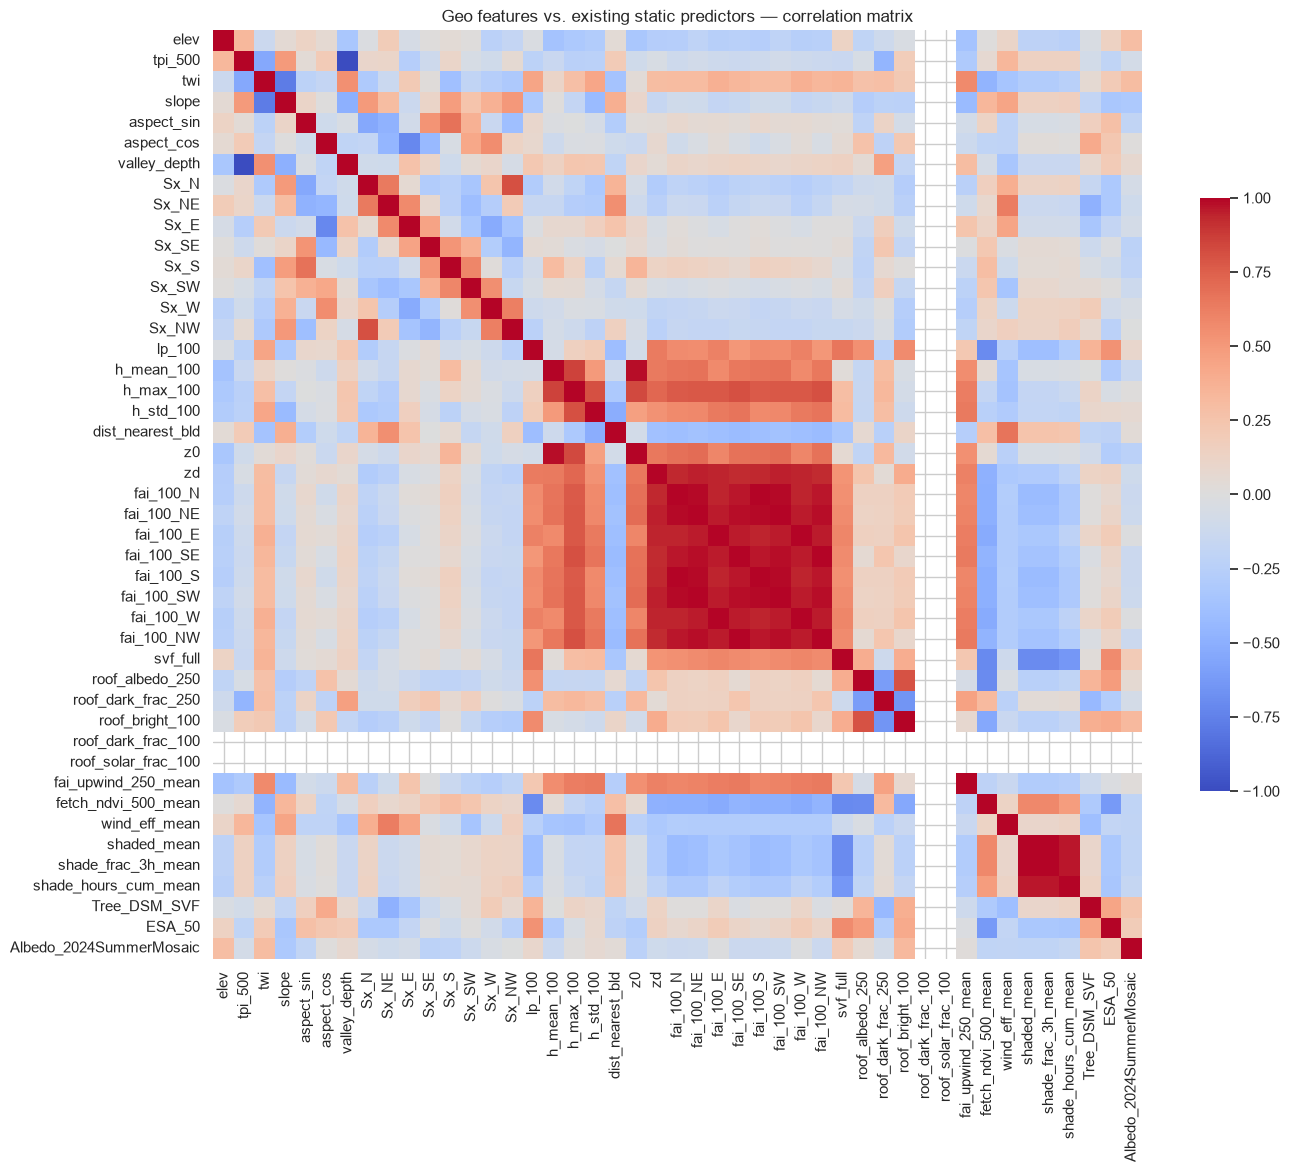

In [3]:
sensor_level = dev.drop_duplicates("Sensor_ID").set_index("Sensor_ID")
check_cols = GEO_ALL_EXPLORE + ["Tree_DSM_SVF", "ESA_50", "Albedo_2024SummerMosaic"]
corr = sensor_level[check_cols].corr()

high_corr = []
for i, a in enumerate(check_cols):
    for b in check_cols[i + 1:]:
        r = corr.loc[a, b]
        if pd.notna(r) and abs(r) > 0.9:
            high_corr.append((a, b, round(float(r), 3)))
print(f"{len(high_corr)} pairs with |r| > 0.9:")
for a, b, r in high_corr:
    print(f"  {a} <-> {b}: r={r}")

plt.figure(figsize=(14, 12))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True,
            cbar_kws={"shrink": 0.6})
plt.title("Geo features vs. existing static predictors — correlation matrix")
plt.tight_layout()
plt.show()


In [4]:
vif_cols = [c for c in check_cols if sensor_level[c].notna().all() and sensor_level[c].std() > 0]
X_vif = sensor_level[vif_cols].dropna()
vif = pd.DataFrame({
    "feature": vif_cols,
    "VIF": [variance_inflation_factor(X_vif.values, i) for i in range(len(vif_cols))],
}).sort_values("VIF", ascending=False)
vif


C:\Users\yosef\AppData\Local\Temp\ipykernel_6140\677413281.py:5: UserWarning: The design matrix is poorly conditioned (condition number=3.97e+15). VIF calculations may be numerically unstable.
  "VIF": [variance_inflation_factor(X_vif.values, i) for i in range(len(vif_cols))],
C:\Users\yosef\Desktop\תואר שני\urban-heat-mapping-research\.venv\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
C:\Users\yosef\Desktop\תואר שני\urban-heat-mapping-research\.venv\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
C:\Users\yosef\Desktop\תואר שני\urban-heat-mapping-research\.venv\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design

,feature,VIF
0,elev,1.000800e+15
1,tpi_500,1.000800e+15
2,twi,1.000800e+15
3,slope,1.000800e+15
4,aspect_sin,1.000800e+15
5,aspect_cos,1.000800e+15
6,valley_depth,1.000800e+15
7,Sx_N,1.000800e+15
8,Sx_NE,1.000800e+15
9,Sx_E,1.000800e+15


If `svf_full` turns out highly collinear with `Tree_DSM_SVF` above, that's
expected — both are sky-view-factor ray-traces over the same sensor
locations; `svf_full` additionally accounts for buildings, which
`Tree_DSM_SVF` (tree canopy only, per the plan's own framing) does not, so
some daylighting is still expected even under high correlation.

## 3. Ablation: inner LOSO over the 27 development sensors

`XGB_PARAMS_FAST` throughout, same as notebook 06. For each held-out sensor:
B1 (baseline), B1+<family> for each of T/M/R/W/S, B1+All (every new column),
and M1+All (B1+All plus notebook 06's leakage-safe network features and F1
temporal features).

In [5]:
def build_fold_network_features(fold_ids, held_out):
    pool = [s for s in fold_ids if s != held_out]
    fold_data = dev[dev["Sensor_ID"].isin(fold_ids)]
    return build_network_features(fold_data, sensor_info, set(pool), target_col="temp_anom",
                                   static_cols=NETWORK_STATIC_COLS)

def fit_with_extra(df, X_NAMES, extra_cols, train_ids, held_out):
    cols = X_NAMES + [c for c in extra_cols if c in df.columns]
    df2 = df.copy()
    train_mask = df2["Sensor_ID"].isin(train_ids)
    for c in extra_cols:
        if c in df2.columns:
            df2[c] = df2[c].fillna(df2.loc[train_mask, c].median())
    return fit_xgb(df2, "temp_anom", cols, XGB_PARAMS_FAST, train_ids, [held_out])

VARIANTS = {"B1": [], "B1+T": GEO_T, "B1+M": GEO_M, "B1+R": GEO_R, "B1+W": GEO_W, "B1+S": GEO_S, "B1+All": GEO_ALL}

def run_ablation(period, base_df=None):
    base = dev if base_df is None else base_df
    X_NAMES = X_NAMES_AT_DAY if period == "day" else X_NAMES_AT_NIGHT
    rows = []
    for held_out in dev_ids:
        train_ids = [s for s in dev_ids if s != held_out]
        net_feat = build_fold_network_features(dev_ids, held_out)
        fold_data = base[base["Sensor_ID"].isin(dev_ids)].merge(
            net_feat, on=["Sensor_ID", "edt_datetime"], how="left")
        fold_data = add_temporal_features(fold_data)
        day_f, night_f = split_day_night(fold_data)
        df = day_f if period == "day" else night_f

        train_df = df[df["Sensor_ID"].isin(train_ids)]
        test_df = df[df["Sensor_ID"] == held_out]
        if len(test_df) == 0 or len(train_df) == 0:
            continue

        for name, extra in VARIANTS.items():
            fit = fit_with_extra(df, X_NAMES, extra, train_ids, held_out)
            resid = fit["pred_test"] - fit["y_test"].values
            rows.append({"period": period, "model": name, "sensor": held_out, "n": len(resid),
                         "RMSE": float(np.sqrt(np.mean(resid ** 2)))})

        m1_features = X_NAMES + GEO_ALL + [c for c in NETWORK_COLS if c in df.columns] + \
            [c for c in TEMPORAL_COLS if c in df.columns]
        m1_features = [c for c in m1_features if c in df.columns]
        df_m1 = df.copy()
        train_mask = df_m1["Sensor_ID"].isin(train_ids)
        for c in m1_features:
            df_m1[c] = df_m1[c].fillna(df_m1.loc[train_mask, c].median())
        fit_m1 = fit_xgb(df_m1, "temp_anom", m1_features, XGB_PARAMS_FAST, train_ids, [held_out])
        resid_m1 = fit_m1["pred_test"] - fit_m1["y_test"].values
        rows.append({"period": period, "model": "M1+All", "sensor": held_out, "n": len(resid_m1),
                     "RMSE": float(np.sqrt(np.mean(resid_m1 ** 2)))})
    return pd.DataFrame(rows)

import os
os.makedirs("../data/results", exist_ok=True)
CACHE_DAY, CACHE_NIGHT = "../data/results/ablation_geo_day.parquet", "../data/results/ablation_geo_night.parquet"
if os.path.exists(CACHE_DAY) and os.path.exists(CACHE_NIGHT):
    ablation_day, ablation_night = pd.read_parquet(CACHE_DAY), pd.read_parquet(CACHE_NIGHT)
else:
    ablation_day = run_ablation("day")
    ablation_night = run_ablation("night")
    ablation_day.to_parquet(CACHE_DAY)
    ablation_night.to_parquet(CACHE_NIGHT)
ablation = pd.concat([ablation_day, ablation_night], ignore_index=True)
print(ablation.shape)


(432, 5)


## 4. Results: per-sensor median RMSE and paired Wilcoxon vs. B1

In [6]:
summary = (ablation.groupby(["period", "model"])["RMSE"]
           .agg(median="median", mean="mean", n_sensors="count").reset_index()
           .sort_values(["period", "median"]))
summary


,period,model,median,mean,n_sensors
7,day,M1+All,0.975406,0.973217,27
0,day,B1,1.042550,1.162947,27
6,day,B1+W,1.052273,1.135101,27
3,day,B1+R,1.067255,1.149307,27
5,day,B1+T,1.071149,1.168829,27
2,day,B1+M,1.081439,1.117243,27
4,day,B1+S,1.084337,1.150848,27
1,day,B1+All,1.130557,1.138163,27
15,night,M1+All,0.448648,0.548514,27
9,night,B1+All,0.479827,0.570070,27


In [7]:
def wilcoxon_vs_b1(df, period):
    b1 = df[(df.period == period) & (df.model == "B1")].set_index("sensor")["RMSE"]
    rows = []
    for model in df.model.unique():
        if model == "B1":
            continue
        other = df[(df.period == period) & (df.model == model)].set_index("sensor")["RMSE"]
        common = b1.index.intersection(other.index)
        if len(common) < 5:
            continue
        stat = paired_wilcoxon(other.loc[common], b1.loc[common])
        improvement = 100 * (b1.loc[common].median() - other.loc[common].median()) / b1.loc[common].median()
        rows.append({"period": period, "model": model, "median_improvement_%": improvement,
                     "wilcoxon_p": stat.pvalue})
    return pd.DataFrame(rows)

wilcoxon_results = pd.concat([wilcoxon_vs_b1(ablation, "day"), wilcoxon_vs_b1(ablation, "night")], ignore_index=True)
wilcoxon_results = wilcoxon_results.sort_values(["period", "median_improvement_%"], ascending=[True, False])
wilcoxon_results


,period,model,median_improvement_%,wilcoxon_p
6,day,M1+All,6.440331,0.000026
3,day,B1+W,-0.932592,0.258371
2,day,B1+R,-2.369668,0.348328
0,day,B1+T,-2.743207,0.877918
1,day,B1+M,-3.730195,0.290081
4,day,B1+S,-4.008212,0.561933
5,day,B1+All,-8.441550,0.530322
13,night,M1+All,13.100967,0.661680
12,night,B1+All,7.061977,0.290081
7,night,B1+T,4.074895,0.990573


In [8]:
def best_family(period):
    sub = wilcoxon_results[(wilcoxon_results.period == period) & (wilcoxon_results.model != "M1+All")]
    sub = sub.sort_values("median_improvement_%", ascending=False)
    return sub.iloc[0] if len(sub) else None

best_day, best_night = best_family("day"), best_family("night")
print("Best day family:\n", best_day)
print("Best night family:\n", best_night)

for period, best in (("day", best_day), ("night", best_night)):
    if best is None or best["model"] == "B1":
        continue
    rmse_best = ablation[(ablation.period == period) & (ablation.model == best["model"])].set_index("sensor")["RMSE"]
    ci = sensor_bootstrap_ci(rmse_best)
    print(f"{period} {best['model']} median RMSE bootstrap CI:", ci)


Best day family:
 period                       day
model                       B1+W
median_improvement_%   -0.932592
wilcoxon_p              0.258371
Name: 3, dtype: object
Best night family:
 period                     night
model                     B1+All
median_improvement_%    7.061977
wilcoxon_p              0.290081
Name: 12, dtype: object
day B1+W median RMSE bootstrap CI: {'median': 1.0522726052114322, 'ci_low': 0.9399365563329924, 'ci_high': 1.2442163325024942}
night B1+All median RMSE bootstrap CI: {'median': 0.4798270100900222, 'ci_low': 0.4261168457060508, 'ci_high': 0.5920285091947702}


## 5. Negative control: permute the best family's columns across sensors

If sensor A's geo-feature values are swapped for a random other dev sensor's
values, any genuine per-sensor spatial signal should be destroyed — the
model can no longer learn "this sensor's actual terrain/morphology/roof/wind
context," only noise correlated with nothing. If the permuted version keeps
most of the real version's improvement over B1, the apparent gain in section
4 was not really coming from genuine per-sensor geo information.

In [9]:
def permute_family(base, family_cols, random_state=42):
    rng = np.random.default_rng(random_state)
    perm_ids = rng.permutation(dev_ids)
    mapping = dict(zip(dev_ids, perm_ids))
    sensor_static = base.drop_duplicates("Sensor_ID").set_index("Sensor_ID")[family_cols]
    permuted = sensor_static.loc[[mapping[s] for s in dev_ids]].copy()
    permuted.index = pd.Index(dev_ids, name="Sensor_ID")
    permuted = permuted.reset_index()
    out = base.drop(columns=family_cols).merge(permuted, on="Sensor_ID", how="left")
    return out

def run_control_for(period, best):
    if best is None or best["model"] in ("B1", "M1+All"):
        return None
    family_key = best["model"].replace("B1+", "")
    family_cols = {"T": GEO_T, "M": GEO_M, "R": GEO_R, "W": GEO_W, "S": GEO_S, "All": GEO_ALL}[family_key]
    family_cols = [c for c in family_cols if c in dev.columns]
    dev_perm = permute_family(dev, family_cols)

    X_NAMES = X_NAMES_AT_DAY if period == "day" else X_NAMES_AT_NIGHT
    rows = []
    for held_out in dev_ids:
        train_ids = [s for s in dev_ids if s != held_out]
        net_feat = build_fold_network_features(dev_ids, held_out)
        fold_data = dev_perm[dev_perm["Sensor_ID"].isin(dev_ids)].merge(
            net_feat, on=["Sensor_ID", "edt_datetime"], how="left")
        day_f, night_f = split_day_night(fold_data)
        df = day_f if period == "day" else night_f
        for name in ("B1", best["model"]):
            extra = [] if name == "B1" else family_cols
            fit = fit_with_extra(df, X_NAMES, extra, train_ids, held_out)
            resid = fit["pred_test"] - fit["y_test"].values
            rows.append({"model": name, "sensor": held_out, "RMSE": float(np.sqrt(np.mean(resid ** 2)))})
    return pd.DataFrame(rows), family_key

for period, best in (("day", best_day), ("night", best_night)):
    result = run_control_for(period, best)
    if result is None:
        print(f"{period}: no non-trivial winning family to test")
        continue
    control_df, family_key = result
    real = ablation[(ablation.period == period) & (ablation.model == best["model"])].set_index("sensor")["RMSE"]
    perm_b1 = control_df[control_df.model == "B1"].set_index("sensor")["RMSE"]
    perm_family = control_df[control_df.model == best["model"]].set_index("sensor")["RMSE"]
    print(f"--- {period}, family {family_key} ---")
    print("Real median RMSE:          ", real.median())
    print("Permuted-control B1 median:", perm_b1.median())
    print("Permuted-control family median:", perm_family.median())
    print("If the permuted-family median is close to permuted-B1 (not to the real median above),")
    print("the apparent gain is destroyed by permutation, as expected for genuine spatial signal.")


--- day, family W ---
Real median RMSE:           1.0522726052114322
Permuted-control B1 median: 1.0425498734534624
Permuted-control family median: 1.0919382842091092
If the permuted-family median is close to permuted-B1 (not to the real median above),
the apparent gain is destroyed by permutation, as expected for genuine spatial signal.


--- night, family All ---
Real median RMSE:           0.4798270100900222
Permuted-control B1 median: 0.5162870865327053
Permuted-control family median: 0.5410957712536248
If the permuted-family median is close to permuted-B1 (not to the real median above),
the apparent gain is destroyed by permutation, as expected for genuine spatial signal.


## 6. SHAP for the winning model

Checks the new features' effect directions are physically sensible, not an
artifact. Subsampled to 8 development sensors' held-out folds (not all 27)
for runtime, same subsampling spirit as notebook 06's overfitting
diagnostic — this is a direction-sanity check, not the headline result.

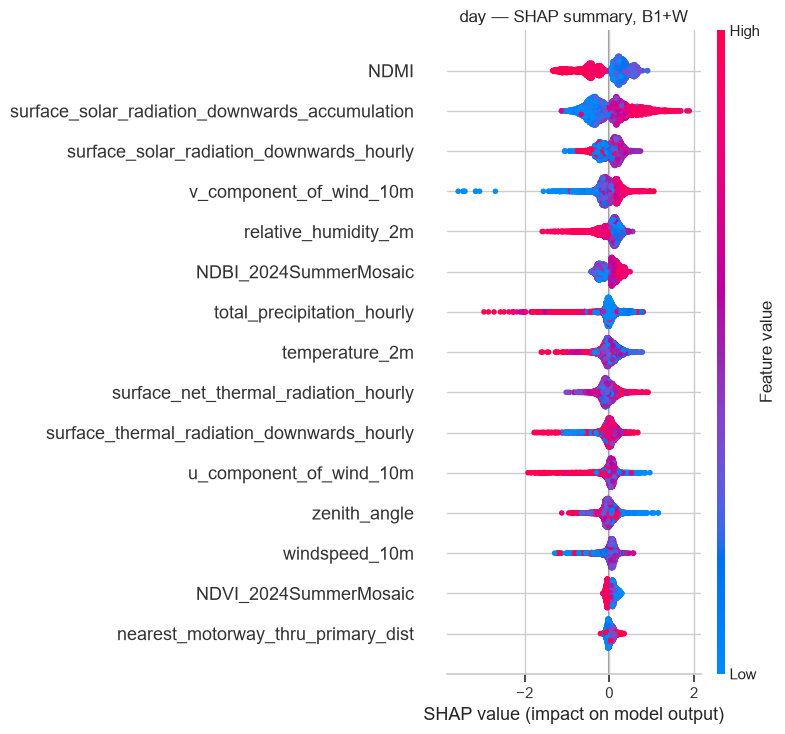

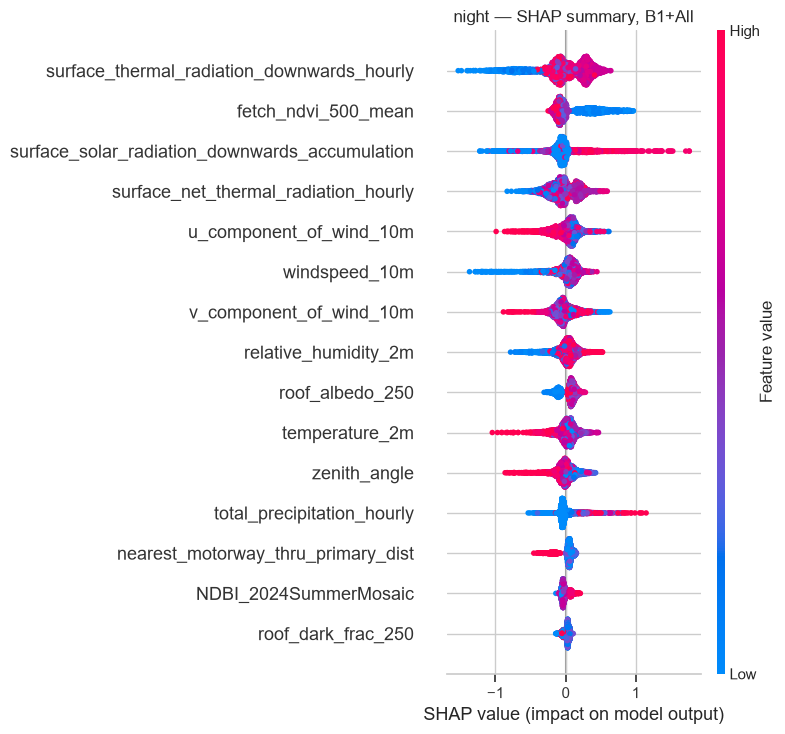

In [10]:
import shap

def shap_for_period(period, best):
    if best is None:
        return None
    X_NAMES = X_NAMES_AT_DAY if period == "day" else X_NAMES_AT_NIGHT
    extra = {"B1": [], "T": GEO_T, "M": GEO_M, "R": GEO_R, "W": GEO_W, "S": GEO_S,
             "All": GEO_ALL}[best["model"].replace("B1+", "") if best["model"] != "M1+All" else "All"]
    sample_sensors = dev_ids[:8]
    all_shap, all_X = [], []
    for held_out in sample_sensors:
        train_ids = [s for s in dev_ids if s != held_out]
        net_feat = build_fold_network_features(dev_ids, held_out)
        fold_data = dev[dev["Sensor_ID"].isin(dev_ids)].merge(
            net_feat, on=["Sensor_ID", "edt_datetime"], how="left")
        fold_data = add_temporal_features(fold_data)
        day_f, night_f = split_day_night(fold_data)
        df = day_f if period == "day" else night_f
        if best["model"] == "M1+All":
            cols = X_NAMES + GEO_ALL + [c for c in NETWORK_COLS if c in df.columns] + \
                [c for c in TEMPORAL_COLS if c in df.columns]
            cols = [c for c in cols if c in df.columns]
        else:
            cols = X_NAMES + [c for c in extra if c in df.columns]
        train_mask = df["Sensor_ID"].isin(train_ids)
        df2 = df.copy()
        for c in cols:
            df2[c] = df2[c].fillna(df2.loc[train_mask, c].median())
        fit = fit_xgb(df2, "temp_anom", cols, XGB_PARAMS_FAST, train_ids, [held_out])
        explainer = shap.TreeExplainer(fit["model"])
        test_mask = df2["Sensor_ID"] == held_out
        X_test_norm = fit["scaler"].transform(df2.loc[test_mask, cols].values)
        sv = explainer.shap_values(X_test_norm)
        all_shap.append(sv)
        all_X.append(df2.loc[test_mask, cols])
    return np.vstack(all_shap), pd.concat(all_X, ignore_index=True)

for period, best in (("day", best_day), ("night", best_night)):
    if best is None or best["model"] == "B1":
        print(f"{period}: no winning family, skipping SHAP")
        continue
    sv, X_sample = shap_for_period(period, best)
    plt.figure()
    shap.summary_plot(sv, X_sample, show=False, max_display=15)
    plt.title(f"{period} — SHAP summary, {best['model']}")
    plt.tight_layout()
    plt.show()


## Summary

Section 4 ranks B1 / B1+T / B1+M / B1+R / B1+W / B1+S / B1+All / M1+All by
inner-LOSO per-sensor RMSE, day and night separately, with paired Wilcoxon
tests against B1. Section 5's sensor-permutation negative control checks
whether the best-performing family's apparent gain survives destroying its
genuine per-sensor spatial correspondence. Section 6's SHAP summary checks
the winning features' effect directions make physical sense.

**W/S caveat (repeated from the top):** the wind and shadow features here
are one-week time-averages per sensor, not true per-hour dynamics — the plan's
original fully time-varying W/S design (`fai_upwind_250(t)`, `shaded(t)`,
etc., joined on `(Sensor_ID, time)`) is not yet wired into the main hourly
ablation. If W or S shows a real, permutation-surviving gain here as a
static proxy, extending `static_geo_durham_dynamic.parquet` to the full
season and re-running with genuine per-hour values is the natural next step
before trusting or freezing this result — this notebook does **not** open
the lockbox (notebook 07) regardless of what it finds.
